Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Realizado por: Alexander Fernández Pérez
# **Unsupervised Learning**
## Mall Customer Clustering with KMeans

### **Introduction**

This activity introduces clustering using the `mall_customers.csv` dataset, which contains information about shopping mall customers, including a variable that represents their spending behavior.

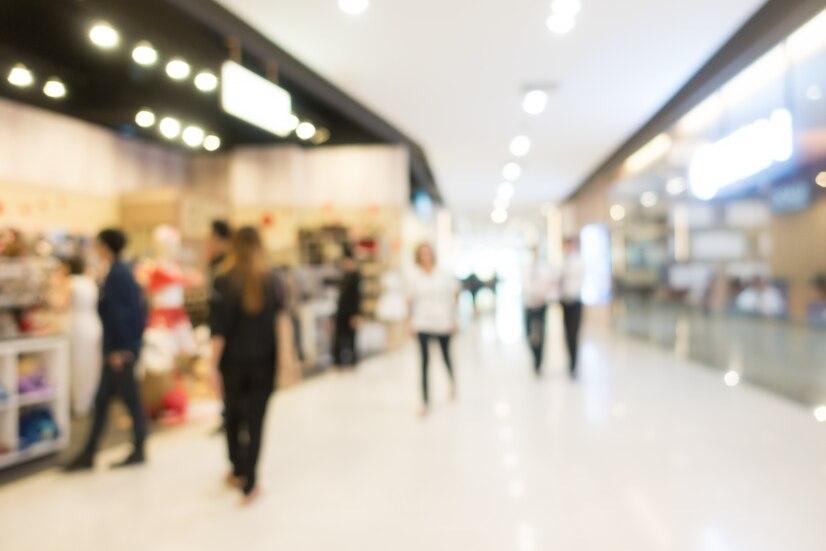

The `mall_customers.csv` dataset contains the following variables:

1. `CustomerID`: A unique identifier for each customer. It is an integer that increases by 1 for each customer.

2. `Gender`: The customer's gender. This is a categorical variable with two possible values: 'Male' and 'Female'.

3. `Age`: The customer's age. This is a numerical variable.

4. `Annual Income (k$)`: The customer's annual income in thousands of dollars. This is a numerical variable.

5. `Spending Score (1-100)`: The customer's spending score on a scale from 1 to 100. This is a numerical variable that indicates how much the customer spends or reflects their purchasing behavior.

The spending score measures how much a customer spends at a particular business over a given period. This metric is essential for understanding customer purchasing behavior and segmenting customers into groups with similar characteristics. But how is this score calculated, and where does it come from in a real company?

The spending score is derived from a combination of factors, such as visit frequency, average purchase value, and total spending over a specific period. Businesses often use customer tracking systems, such as loyalty programs, loyalty cards, or point-of-sale (POS) systems, to collect purchase data. These systems record each customer transaction, including the amount spent, items purchased, and visit frequency.

Using this information, businesses can calculate the spending score in various ways, such as assigning points to each purchase based on its value or frequency, or using more complex algorithms that consider multiple variables. The goal is to create a metric that accurately and meaningfully reflects each customer's purchasing behavior.

In the real world, spending scores are used across many industries, including retail, restaurants, hotels, and financial services. Businesses use them to better understand customers, identify purchasing patterns, design targeted marketing strategies, and improve the customer experience.

### **Content**

#### Import the required packages

In [1]:
# Install the required packages
%pip install scikit-learn
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install ipywidgets
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import the required packages
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#### Load the dataset

In [3]:
# Load the 'mall_customers.csv' dataset
customers = pd.read_csv('mall_customers.csv')

#### Display the first 10 rows of the loaded dataset

In [4]:
# Display the first rows
customers.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [5]:
# Display information about the dataset
customers.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


array([[<Axes: title={'center': 'CustomerID'}>,
        <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Annual Income (k$)'}>,
        <Axes: title={'center': 'Spending Score (1-100)'}>]], dtype=object)

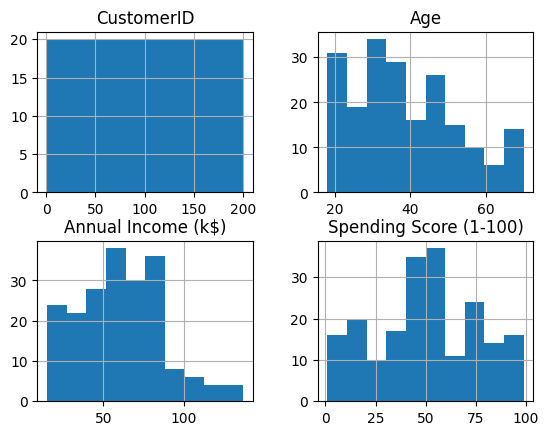

In [6]:
# Display histograms of the variables
customers.hist()

#### Remove columns that do not provide useful information for the analysis

The `CustomerID` column is a unique identifier for each customer. In most cases, identifiers like this do not provide useful information for data analysis or data mining models because they are not related to the other variables. Therefore, this column is commonly removed before analysis.

The pandas `drop` method removes the specified column (`'CustomerID'`) from the DataFrame. The `axis=1` argument indicates that we want to remove a column rather than a row. The resulting DataFrame is assigned back to the `customers` variable.

In [7]:
# Remove the 'CustomerID' column
customers = customers.drop('CustomerID', axis=1)
customers.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
5,Female,22,17,76
6,Female,35,18,6
7,Female,23,18,94
8,Male,64,19,3
9,Female,30,19,72


#### Encode the categorical 'Gender' column

We use the pandas `replace` method to replace values in the `Gender` column of the `customers` DataFrame.

- `customers['Gender']`: Selects the `Gender` column from the `customers` DataFrame.

- `replace({'Female': 0, 'Male': 1})`: Replaces values in the column according to the provided mapping. In this case, it replaces 'Female' with 0 and 'Male' with 1. This is called label encoding.

The purpose of this code is to convert the categorical `Gender` variable into a numerical variable, which is useful for calculating correlations between variables.

In [8]:
# Encode the 'Gender' variable
customers['Gender'] = customers['Gender'].replace({'Female': 0, 'Male': 1})
customers.head(10)

C:\Users\pauls\AppData\Local\Temp\ipykernel_19464\3822190155.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  customers['Gender'] = customers['Gender'].replace({'Female': 0, 'Male': 1})


,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40
5,0,22,17,76
6,0,35,18,6
7,0,23,18,94
8,1,64,19,3
9,0,30,19,72


#### Use `ydata_profiling` to profile the data

The `ydata_profiling` tool is very useful for exploratory data analysis. This Python library generates detailed data profiles from a pandas DataFrame, providing a quick, comprehensive overview of the data structure, relationships, and distributions.

With `ydata_profiling`, you can generate a comprehensive report from your dataset with just a few lines of code. The report includes descriptive statistics, variable distributions, correlations, missing values, and more. This can be extremely useful at the start of any data analysis or data mining project because it helps you understand your data before preprocessing or modeling.

Keep in mind that `ydata_profiling` is a data analysis tool and does not replace careful analysis or a thorough understanding of your data. Always verify and understand the results it provides.

In [9]:
# Install the ydata_profiling library
%pip install ydata-profiling
%pip install setuptools

# Import ProfileReport from ydata_profiling
from ydata_profiling import ProfileReport

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


C:\Users\pauls\AppData\Local\Temp\ipykernel_19464\3948871234.py:6: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


- `customers`: The pandas DataFrame to profile.

- `title='Customer Data Profile Report'`: Sets the report title.

- `explorative=True`: Indicates that the report should be exploratory, including more information and analysis than a standard profiling report.

The data profiling report provides a quick overview of your dataset, including data types, unique values, missing values, descriptive statistics, correlations, and variable distributions.

To display the report, call the `customer_profile` object in a Jupyter Notebook cell.

In [10]:
# Generate the data profiling report
customer_profile = ProfileReport(customers, title='Customer Data Profile Report', explorative=True)

In [11]:
# Display the data profiling report
customer_profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 30559.59it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [12]:
customer_profile.to_file('customer_profile_report.html')

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

#### Plot the distributions of the variables

The distribution of variables in a dataset can provide valuable information about its characteristics. Here are some things to examine:

**Central tendency**: The mean and median indicate where the data are centered.

**Dispersion**: The standard deviation and interquartile range indicate how spread out the data are around the mean.

**Skewness**: A left or right skew may indicate outliers or a non-uniform distribution.

**Outliers**: Values significantly distant from the rest of the data may indicate measurement errors or natural variation.

**Multimodal distribution**: More than one peak may indicate subgroups within the data.

The scatter plot of `Annual Income (k$)` and `Spending Score (1-100)` reveals visible data groupings, suggesting that there are groups of customers with similar spending behavior relative to their annual income.

We create a new DataFrame containing only these two variables to examine these groupings more closely and apply clustering techniques to identify and define the groups more formally.

This can provide valuable information for marketing strategy by allowing customers to be segmented according to their spending behavior and income. This, in turn, can inform decisions about targeted offers and promotions, personalized customer communications, and more.

In [13]:
# Create a DataFrame containing only the 'Annual Income (k$)' and 'Spending Score (1-100)' columns
income_spending = customers[['Annual Income (k$)', 'Spending Score (1-100)']]
income_spending.head(10)

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
5,17,76
6,18,6
7,18,94
8,19,3
9,19,72


#### Plot the distributions of 'Annual Income (k$)' and 'Spending Score (1-100)'

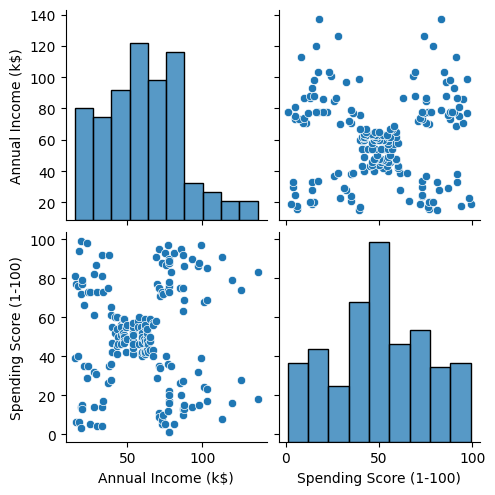

In [14]:
# Plot the distributions in income_spending
sns.pairplot(income_spending)

#### Cluster the 'income_spending' DataFrame using the KMeans algorithm

We use KMeans clustering on the `income_spending` DataFrame to find 2 clusters, then add the cluster labels to the data.

- `kmeans_model = KMeans(n_clusters=2)`: Creates a KMeans model with 2 clusters. The number of clusters is a parameter that must be specified.

- `kmeans_model.fit(income_spending)`: Fits the model to the `income_spending` data. KMeans attempts to find cluster centers that minimize the variance within each cluster.

- `income_spending['Cluster'] = kmeans_model.labels_`: After fitting the model, the `labels_` attribute provides the cluster label for each data point. This line adds the labels as a new column in the `income_spending` DataFrame.

- `income_spending.head(10)`: Displays the first 10 rows of the `income_spending` DataFrame, now including the `Cluster` column.

In [15]:
# Instantiate the KMeans model
kmeans_model = KMeans(n_clusters=2, random_state=75)

# Fit the model to the data
kmeans_model.fit(income_spending)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,75
,copy_x,True
,algorithm,'lloyd'


In [16]:
# Copy the 'income_spending' DataFrame to preserve the original and add the clusters
income_spending_cluster = income_spending.copy()

# Get the cluster labels assigned to each customer
income_spending_cluster['Cluster'] = kmeans_model.labels_

# Display the first rows of 'income_spending_cluster'
income_spending_cluster.head(10)

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,1
1,15,81,1
2,16,6,1
3,16,77,1
4,17,40,1
5,17,76,1
6,18,6,1
7,18,94,1
8,19,3,1
9,19,72,1


In [17]:
income_spending_cluster.tail(10)

,Annual Income (k$),Spending Score (1-100),Cluster
190,103,23,0
191,103,69,0
192,113,8,0
193,113,91,0
194,120,16,0
195,120,79,0
196,126,28,0
197,126,74,0
198,137,18,0
199,137,83,0


We create a pair plot of the `income_spending` variables and color the points according to the clusters identified by KMeans. This helps us visualize how the clusters are distributed in the variable space.

- `sns.pairplot(income_spending)`: Creates a pair plot of all variables in the DataFrame. A pair plot shows the relationship between each pair of variables in a dataset.

- `hue='Cluster'`: Specifies that points in the plot should be colored according to the `Cluster` column. This makes it possible to visualize the distribution of clusters for each pair of variables.

- `palette='viridis'`: Sets the color palette for the clusters. 'viridis' is a perceptually uniform palette that is easy to interpret.

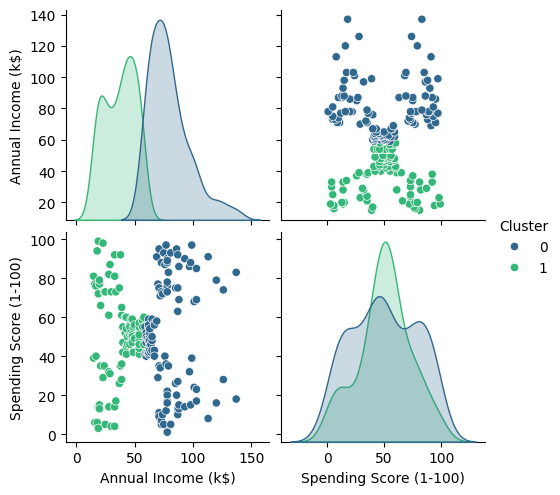

In [18]:
# Display the clusters generated by the KMeans model
sns.pairplot(income_spending_cluster, hue='Cluster', palette='viridis')

In [19]:
# Get the inertia of the KMeans model
inertia = kmeans_model.inertia_
inertia

181363.59595959596

Finally, we can use the previously fitted KMeans model to predict the cluster of a new customer based on their features.

- `new_customer = [ , ]`: Creates a list representing a new customer's data. The values correspond to the customer's annual income and spending score.

- `new_customer_cluster = kmeans_model.predict([new_customer])`: Uses the KMeans model's `predict` method to predict which cluster the new customer belongs to. The method takes a list of lists as input, where each inner list represents one customer's data. Here, the input contains only one customer: `[new_customer]`.

- `print('The new customer belongs to cluster:', new_customer_cluster)`: Prints the cluster assigned to the new customer. The `predict` method returns a list of cluster labels, one for each customer in the input. Here, the list contains a single label.

In [20]:
# New customer with Annual Income (k$) = 50 and Spending Score (1-100) = 50
new_customer_cluster = kmeans_model.predict([[50, 50]])
new_customer_cluster

c:\Users\pauls\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1], dtype=int32)

### **Group Assignment**

We can see that 2 may not be the optimal value of $k$. Let's try to find the best value of $k$ using the elbow method. This method involves running the KMeans clustering algorithm for a range of $k$ values and then plotting the number of clusters against the sum of squared distances within each cluster (inertia).

> Inertia is calculated by measuring the distance between a data point and its centroid, squaring the distance, and summing those squared distances for all data points in the cluster.

The 'elbow' in this plot—the inflection point where the rate of decrease becomes significantly smaller—may indicate a good value for $k$.

### **Code (4 points)**

 k  Inertia  Reduction (%)
 1 269981.0            NaN
 2 181364.0           33.0
 3 106348.0           41.0
 4  73680.0           31.0
 5  44448.0           40.0
 6  37266.0           16.0
 7  30228.0           19.0
 8  25096.0           17.0
 9  21914.0           13.0
10  19968.0            9.0


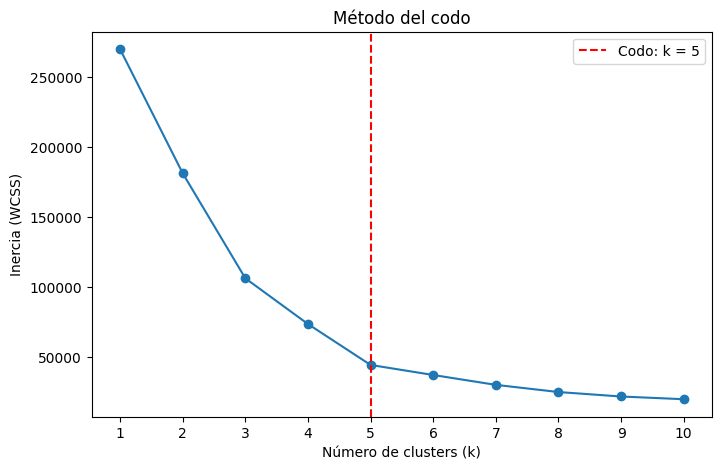

In [24]:
# Write your code here to find the optimal number of clusters using the elbow method.

###############################################################################################
# PASO 1. Método del codo: entrenar KMeans para k = 1, ..., 10
# Para cada k ajustamos un modelo sobre las mismas dos variables (ingreso y gasto)
# y guardamos su inercia (WCSS): la suma de distancias al cuadrado de cada
# cliente a su centroide. A más clusters, menor inercia; buscamos el punto
# donde agregar un cluster más ya casi no reduce la inercia (el "codo").
k_values = range(1, 11)
inertias = []

for k in k_values:
    model_k = KMeans(n_clusters=k, random_state=75, n_init=10)  # n_init=10: 10 inicializaciones, se queda con la mejor
    model_k.fit(income_spending)
    inertias.append(model_k.inertia_)

# Tabla con la inercia y su caída porcentual al pasar de k-1 a k
elbow_table = pd.DataFrame({'k': list(k_values), 'Inertia': inertias})
elbow_table['Reduction (%)'] = (-elbow_table['Inertia'].pct_change() * 100).round(1)
print(elbow_table.round(0).to_string(index=False))

##############################################################################################
# PASO 2. Gráfico del codo
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker='o')
plt.axvline(x=5, color='red', linestyle='--', label='Codo: k = 5')
plt.title('Método del codo')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (WCSS)')
plt.xticks(list(k_values))
plt.legend()
plt.show()

# Lectura: la inercia cae fuerte hasta k = 5 (-40%);
# a partir de k = 6 cada cluster adicional reduce mucho menos (-16%, -19%, -17%...).
# Por eso k = 5, óptimo de clusters.

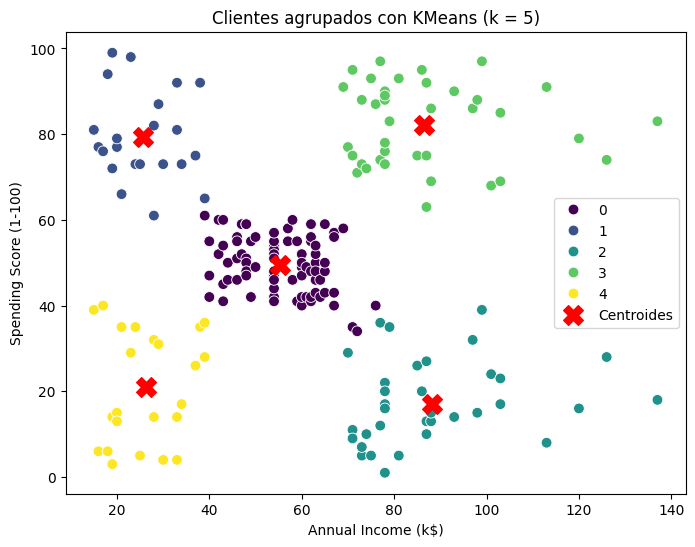

Inercia con k = 5: 44448.5


In [25]:
################################################################################################
# PASO 3. Reentrenar KMeans con el k óptimo (k = 5)
# Reemplazamos el modelo de 2 clusters: a partir de aquí 'kmeans_model' es el de k = 5,
# y es el que se usa para responder las preguntas de análisis.
optimal_k = 5
kmeans_model = KMeans(n_clusters=optimal_k, random_state=75, n_init=10)
kmeans_model.fit(income_spending)

# Añadimos la etiqueta de cluster a una copia del DataFrame
income_spending_cluster = income_spending.copy()
income_spending_cluster['Cluster'] = kmeans_model.labels_

################################################################################################
# PASO 4. Visualizar los clusters y sus centroides
centroids = kmeans_model.cluster_centers_

plt.figure(figsize=(8, 6))
sns.scatterplot(data=income_spending_cluster, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='viridis', s=60)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Centroides')
plt.title(f'Clientes agrupados con KMeans (k = {optimal_k})')
plt.legend()
plt.show()

print('Inercia con k = 5:', round(kmeans_model.inertia_, 1))

In [26]:
#################################################################################################
# PASO 5. Perfil de cada cluster (para interpretar y responder las preguntas)
# Promedio de ingreso y gasto por cluster, más edad y % de hombres usando la tabla 'customers'
# (Gender ya está codificado: 0 = Female, 1 = Male).
cluster_profile = customers.assign(Cluster=kmeans_model.labels_).groupby('Cluster').agg(
    Customers=('Age', 'size'),
    Age=('Age', 'mean'),
    Income=('Annual Income (k$)', 'mean'),
    Spending=('Spending Score (1-100)', 'mean'),
    Male_share=('Gender', lambda g: g.mean() * 100),  # % de hombres
).round(1)

# Nombre descriptivo de cada grupo según su ingreso y gasto promedio
# (el número de cluster que asigna KMeans es arbitrario; el nombre no).
def segment_name(row):
    income = 'Ingreso alto' if row['Income'] > 70 else ('Ingreso bajo' if row['Income'] < 40 else 'Ingreso medio')
    spending = 'gasto alto' if row['Spending'] > 65 else ('gasto bajo' if row['Spending'] < 35 else 'gasto medio')
    return f'{income} - {spending}'

cluster_profile = cluster_profile.rename(columns={'Male_share': 'Male (%)'})
cluster_profile['Segment'] = cluster_profile.apply(segment_name, axis=1)
cluster_profile['Share (%)'] = (cluster_profile['Customers'] / cluster_profile['Customers'].sum() * 100).round(1)
cluster_profile.sort_values('Income')

,Customers,Age,Income,Spending,Male (%),Segment,Share (%)
Cluster,,,,,,,
1,22,25.3,25.7,79.4,40.9,Ingreso bajo - gasto alto,11.0
4,23,45.2,26.3,20.9,39.1,Ingreso bajo - gasto bajo,11.5
0,81,42.7,55.3,49.5,40.7,Ingreso medio - gasto medio,40.5
3,39,32.7,86.5,82.1,46.2,Ingreso alto - gasto alto,19.5
2,35,41.1,88.2,17.1,54.3,Ingreso alto - gasto bajo,17.5


Analysis Questions - New Dataset

Assessment Rubric (10 points)

Phase 1 - Dataset and Features (3 points)
1 point: The dataset is locally sourced, and its source is identified.
1 point: Every dataset variable is described.
1 point: The features selected for the model are justified.

Phase 2 - KMeans Modeling (4 points)
2 points: The elbow method is applied to a range of k values, and the plot and selected k are provided.
2 points: KMeans is fitted using the selected k, and the resulting clusters are visualized.

Phase 3 - Findings (3 points)
1 point each: Three findings are stated, and each is supported by the clustering results.

### **Analysis Questions - Mall Customers Dataset (6 points)**

***1. Which customer group would you focus on?***

En el grupo ingreso alto - gasto bajo, es el grupo con mayor brecha entre capacidad de pago y gasto real, en este grupo no hay que crear capacidad de compra, solo captarla. El ingreso es similar al grupo ingreso alto - gasto alto, pero gasta casi 5 veces menos (17 vs 82).

Los demás grupos tienen un potencial de crecimiento menor: los de ingreso alto con gasto alto ya consumen bastante y solo requieren retención; los de ingresos bajos tienen un margen de gasto limitado; y los de ingreso y gasto medio, aunque son la mayoría, representan una meta secundaria.

***2. What actionable strategies could we recommend to increase spending at the shopping mall?***

Estrategias accionables, por segmento:

1. **Ingreso alto – gasto bajo:** activar ofertas premium y de valor más que descuentos (marcas de calidad, servicios personalizados, eventos exclusivos de lanzamiento); campañas segmentadas para descubrir por qué no compran (encuesta corta en el programa de fidelización).
2. **Ingreso alto – gasto alto:** retener mediante programas de fidelización por niveles (VIP), beneficios exclusivos (estacionamiento, acceso anticipado a rebajas) para evitar que migren a otro centro comercial.
3. **Ingreso medio – gasto medio:** es el grupo más numeroso; promociones de venta cruzada y paquetes (comida + entretenimiento), y puntos que se acumulan por frecuencia de visita.
4. **Ingreso bajo – gasto alto** descuentos y precio accesible, cupones; son jóvenes y responden bien a canales digitales y redes sociales, sin embargo, estar pendiente de no sobrendeudar.
5. **Ingreso bajo – gasto bajo:** ofertas básicas y de bajo costo; no justifica una inversión fuerte de marketing.

***3. Which group would a new customer with an annual income (k$) of 110 and a spending score of 21 belong to?***

In [29]:
# Create a record with the new customer's values and assign it to a cluster using the trained KMeans model.
new_customer = [110, 21] 
# Use the KMeans model's predict method to predict the cluster of the new customer.
new_customer_cluster = kmeans_model.predict([new_customer])

# Mostrar el cluster asignado y el perfil de ese grupo
print('El nuevo cliente pertenece al cluster:', new_customer_cluster[0])
cluster_profile.loc[[new_customer_cluster[0]]]


El nuevo cliente pertenece al cluster: 2


c:\Users\pauls\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


,Customers,Age,Income,Spending,Male (%),Segment,Share (%)
Cluster,,,,,,,
2,35,41.1,88.2,17.1,54.3,Ingreso alto - gasto bajo,17.5


El nuevo cliente (ingreso de 110, spending score de 21) cae en el grupo ingreso alto – gasto bajo.

Analizando, su punto queda junto al centroide de ese grupo (Income = 88; Spending = 17), y lejos del grupo ingreso alto – gasto alto (ingreso de 87, spending score de 82) por la gran diferencia en gasto.

Es el perfil objetivo de la pregunta 1. Por su ingreso, es de los clientes con mayor potencial de aumento de gasto, así que sería prioritario para las estrategias de activación (oferta premium, servicios personalizados y una encuesta para entender por qué no compra más).